# 02 · Obtención de datos ESG y *screening*

**Qué hace este notebook**
1. Construye un universo de inversión (S&P 500) desde una fuente abierta.
2. Documenta los tres métodos que se usaban para descargar *ESG Risk Ratings* de Yahoo Finance y **verifica si siguen disponibles**.
3. Aplica las estrategias básicas de integración ESG sobre una muestra: exclusión, *best-in-class* e inclinación (*tilt*) por score.

> **Aviso (verificado 2026-09-27):** Yahoo Finance dejó de publicar los scores ESG de Sustainalytics a finales de 2025. Los tres métodos devuelven HTTP 404 o datos vacíos. El código se conserva como referencia del método y la sección 3 usa datos de muestra.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esg_workshop.plotting import use_style, SERIES, COOL, WARM, MUTED, INK_2

use_style()
pd.set_option("display.precision", 3)
from esg_workshop import esg_data as ed

## 1. Universo de inversión: S&P 500

La integración ESG empieza por conocer qué emisores del portafolio están expuestos a temas materiales. En producción el universo viene de proveedores de índices o terminales (Bloomberg, LSEG); aquí usamos la tabla pública de Wikipedia.

In [2]:
sp500 = ed.sp500_constituents()
print(f"{len(sp500)} emisores, {sp500.sector.nunique()} sectores GICS")
sp500.head()

503 emisores, 11 sectores GICS


,ticker,name,sector,sub_industry
0,MMM,3M,Industrials,Industrial Conglomerates
1,AOS,A. O. Smith,Industrials,Building Products
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment
3,ABBV,AbbVie,Health Care,Biotechnology
4,ACN,Accenture,Information Technology,IT Consulting & Other Services


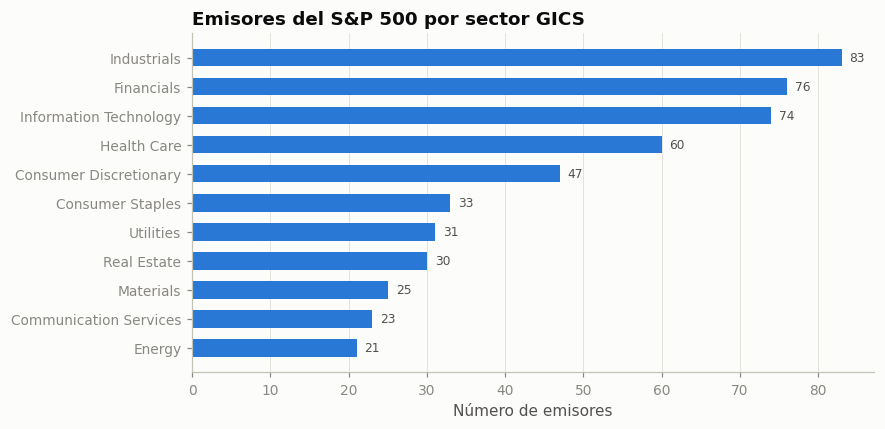

In [3]:
by_sector = sp500.sector.value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(by_sector.index, by_sector.values, color=COOL, height=0.6)
for y_, v in enumerate(by_sector.values):
    ax.text(v + 1, y_, str(v), va="center", fontsize=8, color=INK_2)
ax.set(title="Emisores del S&P 500 por sector GICS", xlabel="Número de emisores"); ax.grid(axis="y", visible=False)
plt.show()

## 2. Scores ESG desde Yahoo Finance (método histórico)

Entre 2018 y 2025 Yahoo mostraba los *ESG Risk Ratings* de Sustainalytics (riesgo total, E, S, G, controversias e involucramiento en productos). Se accedían de tres formas:

| Método | Llamada | Función en `esg_data.py` |
|---|---|---|
| 1. Endpoint `esgChart` | `GET query2.finance.yahoo.com/v1/finance/esgChart?symbol=…` | `yahoo_esg_chart` |
| 2. `yahooquery` | `Ticker(t).esg_scores` | `yahooquery_esg` |
| 3. `yfinance` | `Ticker(t).sustainability` | `yfinance_esg` |

La siguiente celda verifica la disponibilidad usando un módulo no ESG (`assetProfile`) como control positivo: si el control responde 200 y `esgScores` responde 404, el problema no es de conexión sino que el dato ya no existe.

In [4]:
ed.yahoo_esg_available("MSFT")

{'assetProfile': 200,
 'esgScores': 404,
 'esgChart': 404,
 'esg_available': False}

**Alternativas para cursos y proyectos**
- Gratuitas/abiertas: objetivos climáticos de **SBTi** (Target Dashboard), **Net Zero Tracker**, emisiones reportadas a **CDP** (acceso académico), **Climate TRACE**.
- Comerciales: MSCI ESG, Sustainalytics (Morningstar), LSEG/Refinitiv, Bloomberg, S&P Global CSA.
- Las calificaciones de distintos proveedores tienen correlación baja (Berg, Kölbel & Rigobon, 2022): documentar siempre la fuente.

## 3. *Screening* ESG sobre una muestra

Universo anonimizado de 10 emisoras mexicanas (2012–2013) con un **score ESG ilustrativo 0–10** (mayor = mejor).

In [5]:
universe = ed.load_sample_universe()
universe[["ticker", "sector", "industry", "esg_score", "market_cap_mn"]]

,ticker,sector,industry,esg_score,market_cap_mn
0,Stock1,Services,Broadcasting - TV,7.5,14942.50
1,Stock2,Basic Materials,Steel & Iron,5.5,2324.26
2,Stock3,Services,Air Services Other,9.0,1306.83
3,Stock4,Consumer Goods,Beverages - Soft Drinks,6.0,32930.65
4,Stock5,Industrial Goods,Heavy Construction,7.0,1762.64
5,Stock6,Consumer Goods,Meat Products,6.0,1668.50
6,Stock7,Consumer Goods,Processed and Packaged Goods,5.0,2832.29
7,Stock8,Consumer Goods,Beverages - Brewers,4.0,41135.33
8,Stock9,Industrial Goods,Cement,0.0,12688.65
9,Stock10,Technology,Wireless Communications,8.0,78061.35


### 3.1 Exclusión (*negative screening*)
Excluir sectores (p. ej. materiales intensivos en carbono) y emisores por debajo de un umbral.

In [6]:
ed.exclusion_screen(universe, min_score=5, excluded_sectors=["Basic Materials"])[["ticker", "sector", "esg_score"]]

,ticker,sector,esg_score
0,Stock1,Services,7.5
2,Stock3,Services,9.0
3,Stock4,Consumer Goods,6.0
4,Stock5,Industrial Goods,7.0
5,Stock6,Consumer Goods,6.0
6,Stock7,Consumer Goods,5.0
9,Stock10,Technology,8.0


### 3.2 *Best-in-class*
Conservar a los mejores de **cada** sector: mantiene la diversificación sectorial en lugar de excluir industrias completas.

In [7]:
ed.best_in_class(universe, top_fraction=0.5)[["ticker", "sector", "esg_score", "sector_pct_rank"]]

,ticker,sector,esg_score,sector_pct_rank
1,Stock2,Basic Materials,5.5,1.000
2,Stock3,Services,9.0,1.000
3,Stock4,Consumer Goods,6.0,0.875
4,Stock5,Industrial Goods,7.0,1.000
5,Stock6,Consumer Goods,6.0,0.875
9,Stock10,Technology,8.0,1.000


### 3.3 Inclinación (*ESG tilt*)
Partir de pesos por capitalización y sobreponderar los mejores scores: $w_i \propto MC_i\,(s_i/\bar s)^{\lambda}$. Con $\lambda=0$ se recupera el índice por capitalización.

In [8]:
u = universe.set_index("ticker")
tilts = pd.DataFrame({f"λ = {lam}": ed.esg_tilt_weights(u, strength=lam) for lam in (0, 1, 2)})
tilts["esg_score"] = u.esg_score
tilts.assign(**{c: tilts[c].map("{:.1%}".format) for c in tilts.columns[:3]})

,λ = 0,λ = 1,λ = 2,esg_score
ticker,,,,
Stock1,7.9%,9.7%,10.4%,7.5
Stock2,1.2%,1.1%,0.9%,5.5
Stock3,0.7%,1.0%,1.3%,9.0
Stock4,17.4%,17.0%,14.7%,6.0
Stock5,0.9%,1.1%,1.1%,7.0
Stock6,0.9%,0.9%,0.7%,6.0
Stock7,1.5%,1.2%,0.9%,5.0
Stock8,21.7%,14.2%,8.2%,4.0
Stock9,6.7%,0.0%,0.0%,0.0


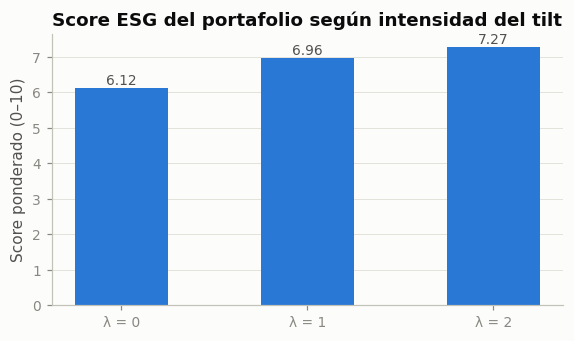

In [9]:
scores = pd.Series({c: (tilts[c] * tilts.esg_score).sum() for c in tilts.columns[:3]})
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(scores.index, scores.values, color=COOL, width=0.5)
for x_, v in enumerate(scores.values):
    ax.text(x_, v + 0.1, f"{v:.2f}", ha="center", fontsize=9, color=INK_2)
ax.set(title="Score ESG del portafolio según intensidad del tilt", ylabel="Score ponderado (0–10)"); ax.grid(axis="x", visible=False)
plt.show()

## Conclusiones
- Los datos ESG gratuitos son frágiles: una fuente puede desaparecer sin aviso. En un proceso de inversión real se contrata un proveedor y se documenta su metodología.
- Exclusión, *best-in-class* y *tilt* son decisiones distintas con efectos distintos en diversificación y *tracking error*; el notebook 03 cuantifica el costo en riesgo de exigir un score mínimo.